<div style="display: flex; align-items: center; justify-content: space-between; border-bottom: 2px solid #0056b3; padding-bottom: 15px; margin-bottom: 20px;">
    <div>
        <h1 style="color: #0056b3; margin: 0;">Análise de Risco Climático para Obras</h1>
        <h3 style="color: #555; margin: 5px 0 0 0;">Gestor de Operações e Negócios Orientado a Dados</h3>
        <p style="margin: 5px 0 0 0; font-size: 14px;">
            <b>Site:</b> <a href="https://www.silvaniogois.com.br" target="_blank">silvaniogois.com.br</a> | 
            <b>Linkedin:</b> <a href="https://www.linkedin.com/in/silvanio-gois" target="_blank">silvanio-gois</a> | 
            <b>Github:</b> <a href="https://github.com/SilvanioSG" target="_blank">SilvanioSG</a> | 
            <b>E-mail:</b> sg@silvaniogois.com.br
        </p>
    </div>
    <div>
        <img src="SG_Site.png" alt="Logo Silvanio Gois" width="120" style="border-radius: 8px;">
    </div>
</div>

### Configuração do Ambiente e Diretórios

In [2]:
import os
import warnings
import matplotlib.pyplot as plt
import pandas as pd
import requests
import seaborn as sns

warnings.filterwarnings("ignore")

# Definindo o diretório de trabalho do projeto
BASE_DIR = r"D:\DIVERSOS\Cases_Portfolio\EstudoMeteorologico"
os.makedirs(BASE_DIR, exist_ok=True)

print(f"Ambiente configurado. Os arquivos serão salvos em: {BASE_DIR}")

Ambiente configurado. Os arquivos serão salvos em: D:\DIVERSOS\Cases_Portfolio\EstudoMeteorologico


### Extração de Dados via API Open-Meteo
**Objetivo: Coletar o histórico horário de precipitação e rajadas de vento dos últimos anos para
a região de estudo (ex: Cubatão/SP), salvando a base bruta em CSV para fins de auditoria e reprodutibilidade.**

In [4]:
# Coordenadas geográficas de referência (Cubatão / SP)
LATITUDE = -23.8931
LONGITUDE = -46.4244
START_DATE = "2022-01-01"
END_DATE = "2025-12-31"

url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": LATITUDE,
    "longitude": LONGITUDE,
    "start_date": START_DATE,
    "end_date": END_DATE,
    "hourly": "precipitation,wind_gusts_10m",
    "timezone": "America/Sao_Paulo",
}

print("Baixando dados meteorológicos da API Open-Meteo...")
response = requests.get(url, params=params)
data = response.json()

# Construção do DataFrame bruto
df = pd.DataFrame(
    {
        "datetime": pd.to_datetime(data["hourly"]["time"]),
        "precipitation_mm": data["hourly"]["precipitation"],
        "wind_gusts_kmh": data["hourly"]["wind_gusts_10m"],
    }
)

# Salvando a base bruta
csv_path = os.path.join(BASE_DIR, "dados_meteorologicos_brutos.csv")
df.to_csv(csv_path, index=False)
print(f"Dados brutos salvos com sucesso em: {csv_path}")
display(df.head())

Baixando dados meteorológicos da API Open-Meteo...
Dados brutos salvos com sucesso em: D:\DIVERSOS\Cases_Portfolio\EstudoMeteorologico\dados_meteorologicos_brutos.csv


,datetime,precipitation_mm,wind_gusts_kmh
0,2022-01-01 00:00:00,0.1,8.6
1,2022-01-01 01:00:00,0.0,11.5
2,2022-01-01 02:00:00,0.0,8.6
3,2022-01-01 03:00:00,0.0,8.3
4,2022-01-01 04:00:00,0.2,13.7


### Engenharia de Atributos Temporais e Limiares de Alerta
**Objetivo: Extrair variáveis temporais detalhadas (ano, mês, dia da semana, hora) 
e estabelecer critérios técnicos de paralisação de obra (ex: chuva > 5mm/h ou ventos fortes > 40km/h) 
para quantificar as janelas de risco.**

In [5]:
# Extração de componentes temporais
df["ano"] = df["datetime"].dt.year
df["mes"] = df["datetime"].dt.month
df["nome_mes"] = df["datetime"].dt.strftime("%B")
df["dia_semana"] = df["datetime"].dt.day_name()
df["hora"] = df["datetime"].dt.hour

# Definindo limiares operacionais padrão para paralisação de serviços externos
LIMIAR_CHUVA = 5.0  # mm/h
LIMIAR_VENTO = 40.0  # km/h

df["alerta_paralisacao"] = (
    (df["precipitation_mm"] >= LIMIAR_CHUVA)
    | (df["wind_gusts_kmh"] >= LIMIAR_VENTO)
).astype(int)

print(
    f"Total de registros analisados: {len(df):,}".replace(",", ".")
)
print(
    f"Total de horas com alerta de paralisação: {df['alerta_paralisacao'].sum():,}".replace(
        ",", "."
    )
)

Total de registros analisados: 35.064
Total de horas com alerta de paralisação: 1.035


### Análise 1 - Sazonalidade Mensal
**Objetivo: Identificar quais meses do ano concentram os maiores volumes de chuva e incidência de alertas, permitindo ao gestor planejar etapas críticas (como terraplenagem e fundações) para os períodos de menor vulnerabilidade.**

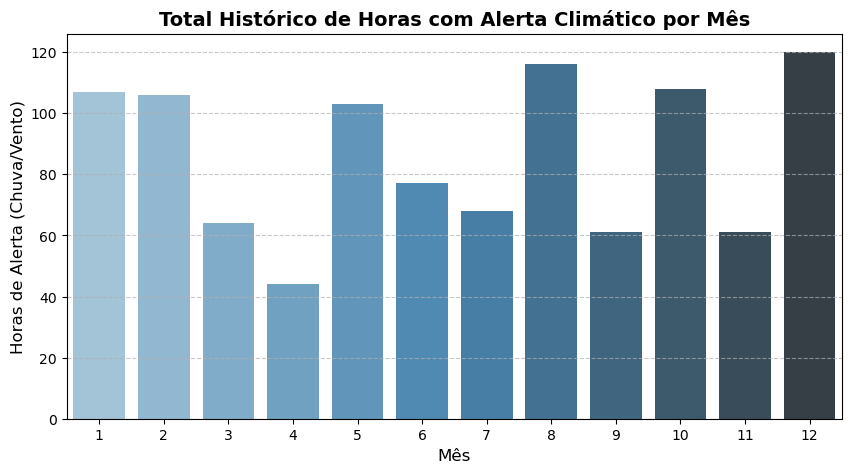

Gráfico salvo em: D:\DIVERSOS\Cases_Portfolio\EstudoMeteorologico\sazonalidade_mensal_alerta.png


In [6]:
# Agrupamento mensal
sazonalidade_mes = (
    df.groupby("mes")
    .agg(
        chuva_acumulada_mm=("precipitation_mm", "sum"),
        media_chuva_horaria=("precipitation_mm", "mean"),
        horas_alerta=("alerta_paralisacao", "sum"),
    )
    .reset_index()
)

# Gráfico de Sazonalidade Mensal
plt.figure(figsize=(10, 5))
sns.barplot(
    x="mes",
    y="horas_alerta",
    data=sazonalidade_mes,
    palette="Blues_d",
)
plt.title(
    "Total Histórico de Horas com Alerta Climático por Mês",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Mês", fontsize=12)
plt.ylabel("Horas de Alerta (Chuva/Vento)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)

chart_path_1 = os.path.join(BASE_DIR, "sazonalidade_mensal_alerta.png")
plt.savefig(chart_path_1, dpi=300, bbox_inches="tight")
plt.show()
print(f"Gráfico salvo em: {chart_path_1}")

### Análise 2 - Ciclo Diurno de Risco
**Objetivo: Mapear o comportamento das intempéries ao longo das 24 horas do dia. Em regiões tropicais, temporais tendem a se concentrar no período da tarde devido ao aquecimento diurno, impactando diretamente o turno de trabalho das equipes.**

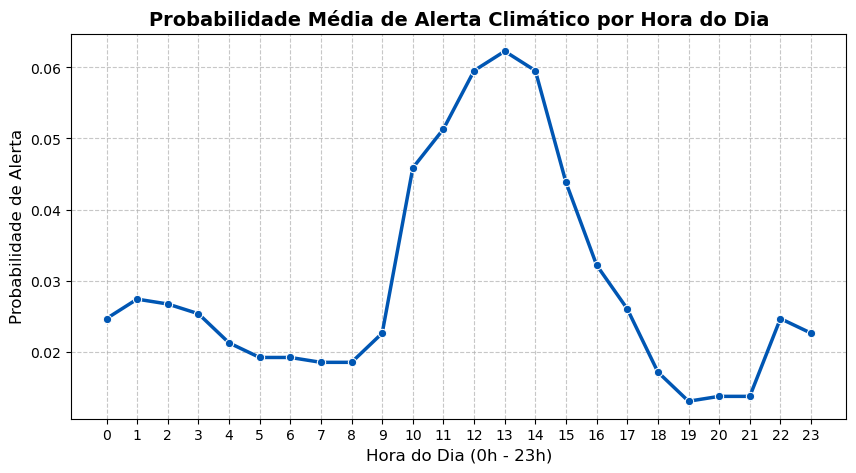

Gráfico salvo em: D:\DIVERSOS\Cases_Portfolio\EstudoMeteorologico\ciclo_diurno_risco.png


In [7]:
# Agrupamento por hora do dia
risco_por_hora = df.groupby("hora")["alerta_paralisacao"].mean().reset_index()

# Gráfico de Linha - Ciclo Diurno
plt.figure(figsize=(10, 5))
sns.lineplot(
    x="hora",
    y="alerta_paralisacao",
    data=risco_por_hora,
    marker="o",
    color="#0056b3",
    linewidth=2.5,
)
plt.title(
    "Probabilidade Média de Alerta Climático por Hora do Dia",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Hora do Dia (0h - 23h)", fontsize=12)
plt.ylabel("Probabilidade de Alerta", fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle="--", alpha=0.7)

chart_path_2 = os.path.join(BASE_DIR, "ciclo_diurno_risco.png")
plt.savefig(chart_path_2, dpi=300, bbox_inches="tight")
plt.show()
print(f"Gráfico salvo em: {chart_path_2}")

### Análise 3 - Heatmap: Meses vs. Horas do Dia
**Objetivo: Criar um mapa de calor cruzando Meses e Horas, revelando visualmente as janelas exatas de maior criticidade operacional (os chamados "pontos cegos" do cronograma) para tomada de decisão gerencial.**

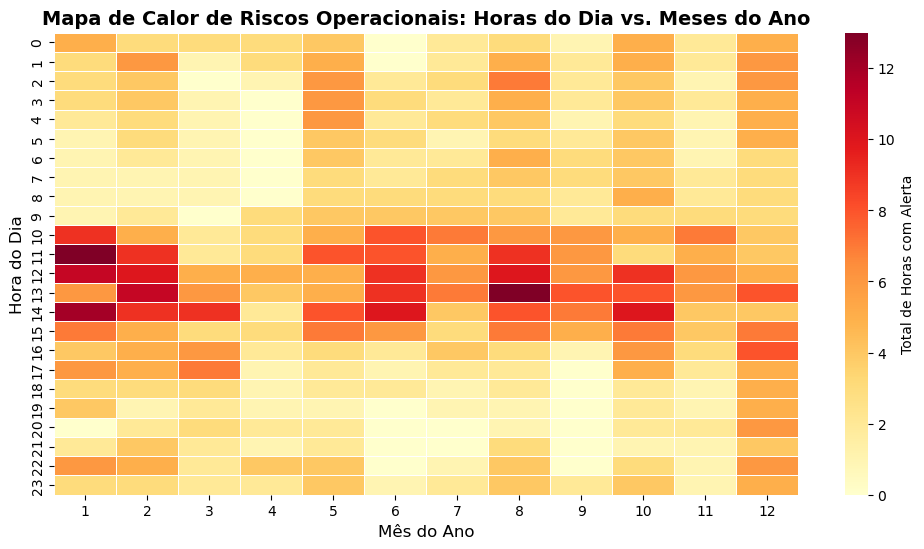

Heatmap salvo em: D:\DIVERSOS\Cases_Portfolio\EstudoMeteorologico\heatmap_risco_mes_hora.png


In [8]:
# Tabela pivô para o Heatmap
pivot_heatmap = df.pivot_table(
    index="hora", columns="mes", values="alerta_paralisacao", aggfunc="sum"
)

# Plotando o Heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(
    pivot_heatmap,
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Total de Horas com Alerta"},
)
plt.title(
    "Mapa de Calor de Riscos Operacionais: Horas do Dia vs. Meses do Ano",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Mês do Ano", fontsize=12)
plt.ylabel("Hora do Dia", fontsize=12)

chart_path_3 = os.path.join(BASE_DIR, "heatmap_risco_mes_hora.png")
plt.savefig(chart_path_3, dpi=300, bbox_inches="tight")
plt.show()
print(f"Heatmap salvo em: {chart_path_3}")

### Modelagem Preditiva com Machine Learning - XGBoost
**Objetivo: Desenvolver e treinar um modelo preditivo capaz de classificar dias críticos para a execução da obra, utilizando métricas de desempenho (Acurácia, Matriz de Confusão e Feature Importance) para demonstrar domínio técnico em ciência de dados aplicada à gestão de operações.**

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   -- ------------------------------------- 2.6/48.9 MB 18.0 MB/s eta 0:00:03
   --- ------------------------------------ 4.5/48.9 MB 12.4 MB/s eta 0:00:04
   ----- ---------------------------------- 7.1/48.9 MB 13.0 MB/s eta 0:00:04
   -------- ------------------------------- 10.2/48.9 MB 13.1 MB/s eta 0:00:03
   ----------- ---------------------------- 13.9/48.9 MB 13.9 MB/s eta 0:00:03
   -------------- ------------------------- 17.8/48.9 MB 14.9 MB/s eta 0:00:03
   ------------------ --------------------- 22.3/48.9 MB 15.8 MB/s eta 0:00:02
   --------------------- ------------------ 26.2/48.9 MB 16.2 MB/s eta 0:00:02
   ------------------------ --------------- 30.4/48.9 MB 16.6 MB/s eta 0:00:02
   -------------------------- ------------- 32.2/48.9 MB 15.8 MB/s eta 0:00:02
   --------------------------- ------------ 33.6/48.9 MB 14.9 MB/s eta 0:00:02
   ---------------------------- ----------- 34.9/48.9 MB 14.4 MB

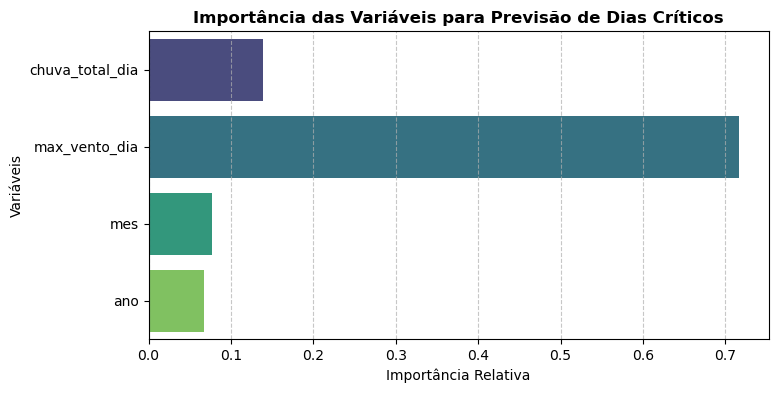

Gráfico de Importância salvo em: D:\DIVERSOS\Cases_Portfolio\EstudoMeteorologico\feature_importance_xgboost.png


In [10]:
!pip install xgboost
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

# Agrupando os dados por dia para prever o risco diário
df["data"] = df["datetime"].dt.date

df_diario = (
    df.groupby("data")
    .agg(
        chuva_total_dia=("precipitation_mm", "sum"),
        max_vento_dia=("wind_gusts_kmh", "max"),
        horas_alerta_dia=("alerta_paralisacao", "sum"),
        mes=("mes", "first"),
        ano=("ano", "first"),
    )
    .reset_index()
)

# Definindo um dia crítico como aquele que acumulou 3 ou mais horas de paralisação
LIMIAR_DIA_CRITICO = 3
df_diario["dia_critico"] = (
    df_diario["horas_alerta_dia"] >= LIMIAR_DIA_CRITICO
).astype(int)

# Selecionando features (recursos) e target (alvo)
X = df_diario[["chuva_total_dia", "max_vento_dia", "mes", "ano"]]
y = df_diario["dia_critico"]

# Divisão de treino e teste (80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Instanciando e treinando o modelo XGBoost
modelo_xgb = XGBClassifier(random_state=42, eval_metric="logloss")
modelo_xgb.fit(X_train, y_train)

# Avaliação do Modelo
y_pred = modelo_xgb.predict(X_test)
print("Relatório de Classificação do Modelo (XGBoost):\n")
print(classification_report(y_test, y_pred))

# Gráfico de Importância das Variáveis (Feature Importance)
plt.figure(figsize=(8, 4))
sns.barplot(
    x=modelo_xgb.feature_importances_,
    y=X.columns,
    palette="viridis",
    hue=X.columns,
    legend=False,
)
plt.title(
    "Importância das Variáveis para Previsão de Dias Críticos",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Importância Relativa", fontsize=10)
plt.ylabel("Variáveis", fontsize=10)
plt.grid(axis="x", linestyle="--", alpha=0.7)

chart_path_4 = os.path.join(BASE_DIR, "feature_importance_xgboost.png")
plt.savefig(chart_path_4, dpi=300, bbox_inches="tight")
plt.show()
print(f"Gráfico de Importância salvo em: {chart_path_4}")

<hr style="border: 1px solid #0056b3;">

<h2> Conclusão e Resumo Metodológico: Gestão de Riscos Climáticos na Construção Civil</h2>

<p>Este estudo desenvolveu um pipeline analítico de ponta a ponta — desde a ingestão automatizada de dados meteorológicos históricos até a modelagem preditiva com Machine Learning — para antecipar paralisações e desvios de cronograma causados por intemperites climáticas.</p>

<h3>1. Escopo Geográfico e Origem dos Dados</h3>
<ul>
    <b>Área de Abrangência Geográfica:</b> Município de Cubatão e região da Baixada Santista / Estado de São Paulo (<tt>Lat: -23.8931, Lon: -46.4244</tt>). Região caracterizada por forte pluviosidade sazonal e suscetibilidade a ventos costeiros e rajadas severas.
    <li><b>Fonte dos Dados Meteorológicos:</b> Open-Meteo Historical Weather API, utilizando séries horárias reais consolidadas de precipitação acumulada (mm/h) e rajadas de vento (km/h).</li>
    <li><b>Reprodutibilidade:</b> A base de dados bruta foi tratada, limpa e persistida localmente no diretório <tt>D:\DIVERSOS\Cases_Portfolio\EstudoMeteorologico</tt> para auditoria e reuso.</li>
</ul>

<h3>2. Resumo da Metodologia Aplicada</h3>
<ol>
    <li><b>Engenharia de Atributos (Feature Engineering):</b> Extração temporal detalhada (anos, meses, dias da semana e ciclos horários de 24h) para capturar a sazonalidade e o comportamento diurno das chuvas.</li>
    <li><b>Definição de Limiares Operacionais:</b> Estabelecimento de critérios técnicos de paralisação baseados em práticas de engenharia de obras (ex: chuva horária >= 5.0 mm/h ou rajadas de vento >= 40.0 km/h).</li>
    <li><b>Análise Exploratória Visual (EDA):</b> Mapeamento de sazonalidade mensal, perfil de risco diário por horário e cruzamento em <i>Heatmap</i> para identificar os "pontos cegos" e janelas críticas do cronograma físico.</li>
    <li><b>Modelagem Preditiva (Machine Learning):</b> Treinamento de um classificador supervisionado baseado no algoritmo <b>XGBoost</b>, mapeando variáveis diárias para prever a probabilidade de dias críticos com risco de paralisação.</li>
</ol>

<h3>3. Como Interpretar os Resultados</h3>
<ul>
    <li><b>Métricas do Modelo (Classification Report):</b> O modelo prioriza o equilíbrio entre <i>Precision</i> (evitar alarmes falsos que geram ociosidade desnecessária de equipes) e <i>Recall</i> (garantir alta cobertura para não deixar dias críticos passarem despercebidos).</li>
    <li><b>Probabilidade de Risco (%):</b> Saída probabilística contínua que serve como gatilho gerencial para o planejamento de curto prazo (médio/curto prazo nas últimas 24 a 72 horas).</li>
</ul>

<h3>4. Como Realizar Testes e Evoluções Futuras</h3>
<p>Para expandir ou testar novas hipóteses com este modelo em projetos futuros, recomenda-se:</p>
<ul>
    <li><b>Validação Cruzada Temporal (<tt>TimeSeriesSplit</tt>):</b> Substituir a divisão aleatória por uma validação que respeite estritamente a ordem cronológica, evitando qualquer viés de data <i>leakage</i>.</li>
    <li><b>Inclusão de Variáveis Adicionais:</b> Incorporar dados de umidade relativa do ar, pressão atmosférica (indicadora de frentes frias) e médias móveis de precipitação dos 3 dias anteriores (para estimar saturação e encharcamento do solo em terraplenagem).</li>
    <li><b>Integração com RDO (Relatório Diário de Obra):</b> Cruzar estas previsões climáticas diretamente com dados reais de avanço físico de cronograma e apontamentos de horas paradas para calcular o impacto financeiro exato (Custo de Ociosidade).</li>
</ul>

<hr style="border: 1px solid #0056b3;">